TASK 1: DATA CLEANING PROJECT

Dataset: Sample - Superstore.csv
Language: Python 3.x
Libraries: Pandas, NumPy, Seaborn, Matplotlib
Environment: Google Colab / Jupyter Notebook

1. Objective

The objective of this project is to take a raw dataset and transform it into a clean, organized and analysis-ready dataset using Python Pandas.

The project includes identifying missing values, removing duplicates, correcting data types, detecting outliers, encoding categorical variables and exporting the cleaned dataset.



In [ ]:
# 2. Load the Dataset and Perform Initial Exploration

#Objective: Load the raw CSV file and understand its structure

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Load Dataset
df = pd.read_csv("/content/superstore_dirty_308_rows.csv")

In [ ]:
# Statistical Summary
print(df.describe())

           Row_ID   Postal_Code    Quantity      Profit
count  308.000000    296.000000  308.000000  299.000000
mean   151.022727  75301.790541    5.535714   55.497090
std     86.213107  23323.266792    2.756459  186.803142
min      1.000000  10001.000000    1.000000 -417.280000
25%     76.750000  75201.000000    3.000000  -45.300000
50%    151.500000  78701.000000    5.000000   24.960000
75%    224.250000  92101.000000    8.000000  153.920000
max    300.000000  98101.000000   10.000000  570.530000



* import pandas: Used for data manipulation.

* read_csv(): Loads the CSV dataset.

* head(): Displays the first five rows.

* info(): Shows column names and data types.

* describe(): Displays statistical information.

* shape: Shows the number of rows and columns.









In [ ]:
# 3. Visualize Missing Data

df.isnull().sum()

,0
Row_ID,0
Order_ID,0
Order_Date,0
Ship_Date,0
Ship_Mode,6
Customer_ID,0
Customer_Name,9
Segment,0
Country,0
City,5


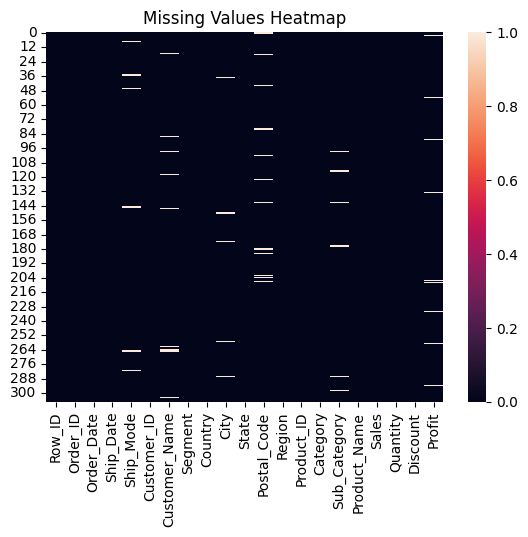

In [ ]:
# heatmap for missing values
sns.heatmap(df.isnull())
plt.title('Missing Values Heatmap')
plt.show()



In [ ]:
# Removing and filling missing values

# Fill missing Ship Mode with most common value
df["Ship_Mode"] = df["Ship_Mode"].fillna(df["Ship_Mode"].mode()[0])

# Fill missing text values with Unprintknown
df["Customer_Name"] = df["Customer_Name"].fillna("Unknown")
df["City"] = df["City"].fillna("Unknown")
df["Sub_Category"] = df["Sub_Category"].fillna("Unknown")

# Fill missing Postal Code with 0
df["Postal_Code"] = df["Postal_Code"].fillna(0)

# Fill missing Profit with median value
df["Profit"] = df["Profit"].fillna(df["Profit"].median())

print(df.isnull().sum())

Row_ID           0
Order_ID         0
Order_Date       0
Ship_Date        0
Ship_Mode        0
Customer_ID      0
Customer_Name    0
Segment          0
Country          0
City             0
State            0
Postal_Code      0
Region           0
Product_ID       0
Category         0
Sub_Category     0
Product_Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


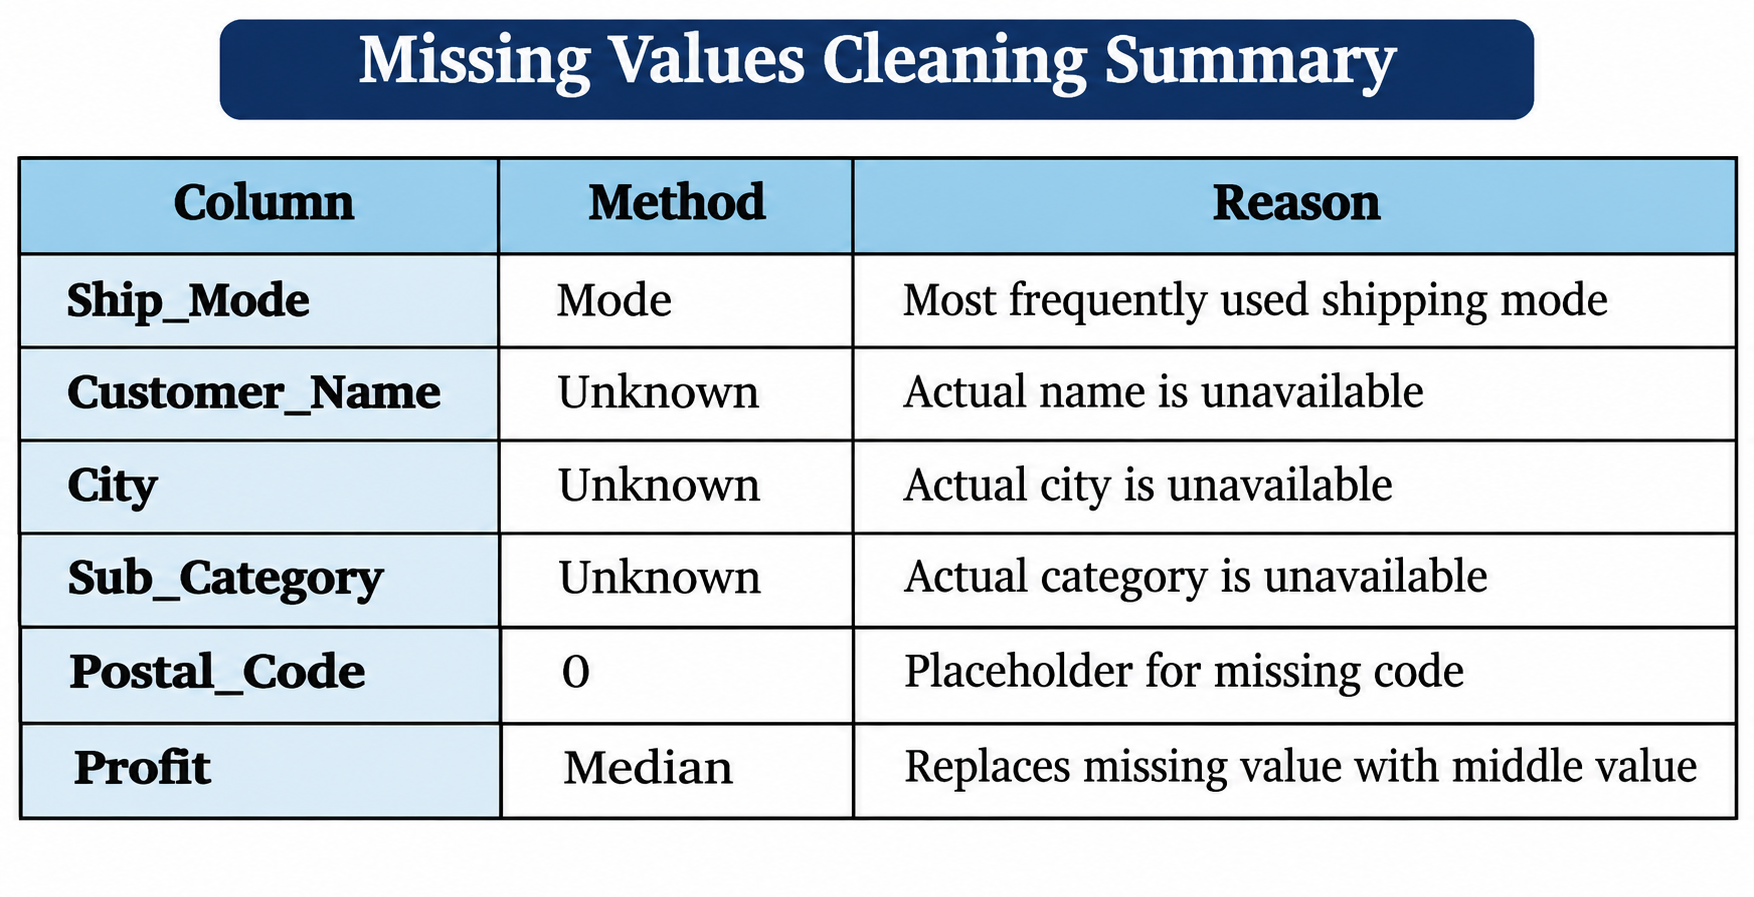

In [ ]:
# 5 . Handling Duplicates

df.duplicated()
df = df.drop_duplicates()

print(df.duplicated().sum())

0


In [ ]:
# 6 . Correct Column Names

df.columns = df.columns.str.strip()
df.columns = df.columns.str.lower()
df.columns = df.columns.str.replace(' ', '_')

print(df.columns)

Index(['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode',
       'customer_id', 'customer_name', 'segment', 'country', 'city', 'state',
       'postal_code', 'region', 'product_id', 'category', 'sub_category',
       'product_name', 'sales', 'quantity', 'discount', 'profit'],
      dtype='object')


Explanation: This changes column names into simple lowercase names.

For example:
- Order Date → order_date
- Customer Name → customer_name
- Product Name → product_name

In [ ]:
# 7.Correct The Data TYpes

df.dtypes

,0
row_id,int64
order_id,object
order_date,object
ship_date,object
ship_mode,object
customer_id,object
customer_name,object
segment,object
country,object
city,object


In [ ]:
df["sales"] = pd.to_numeric(df["sales"], errors="coerce")

df["profit"] = pd.to_numeric(df["profit"], errors="coerce")

df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

print(df.dtypes)

row_id                    int64
order_id                 object
order_date       datetime64[ns]
ship_date                object
ship_mode                object
customer_id              object
customer_name            object
segment                  object
country                  object
city                     object
state                    object
postal_code             float64
region                   object
product_id               object
category                 object
sub_category             object
product_name             object
sales                   float64
quantity                  int64
discount                 object
profit                  float64
dtype: object


Explanation: This converts Sales and Profit into numeric values and order date into datetime format so we can perform calculations.

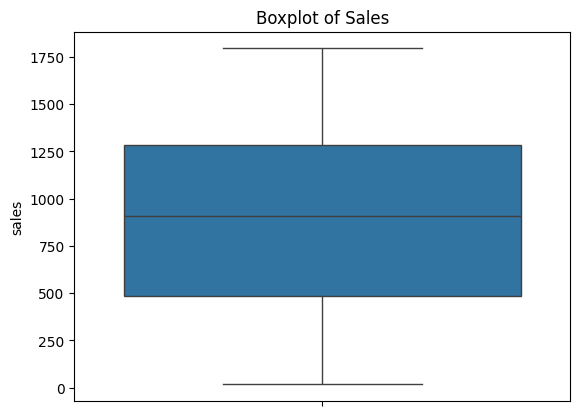

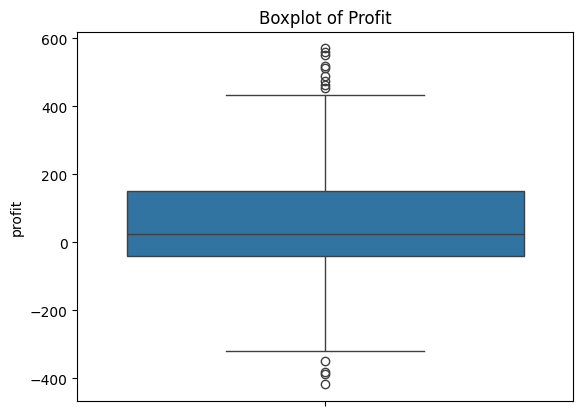

In [ ]:
# 8. Handle Outliers
sns.boxplot(df["sales"])
plt.title("Boxplot of Sales")
plt.show()

sns.boxplot(df["profit"])
plt.title("Boxplot of Profit")
plt.show()

In [ ]:
# we can handle outliers with IQR Method

Q1 = df["sales"].quantile(0.25)

Q3 = df["sales"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR

upper = Q3 + 1.5 * IQR

df["sales"] = df["sales"].clip(lower, upper)
df["profit"] = df["profit"].clip(lower, upper)



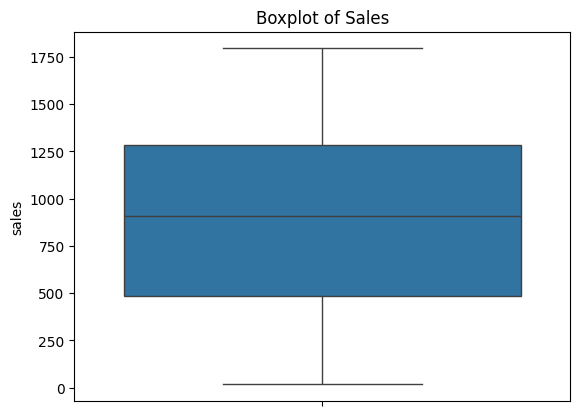

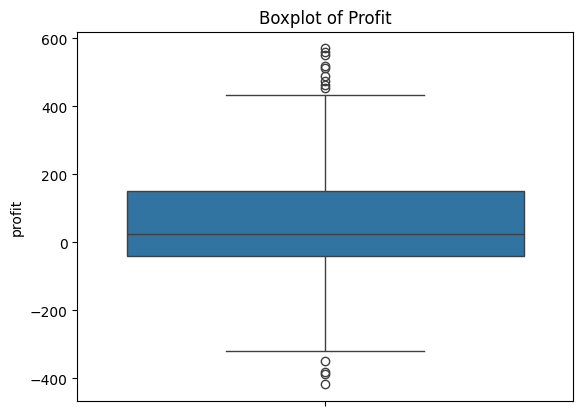

In [ ]:
sns.boxplot(df["sales"])
plt.title("Boxplot of Sales")
plt.show()

sns.boxplot(df["profit"])
plt.title("Boxplot of Profit")
plt.show()

In [ ]:
# 9. Encoding Categorical data



In [ ]:
# Identify Categorical columns
# This displays columns containing text or categorical values

cat_columns =df.select_dtypes(include=["object"]).columns

print(cat_columns)

Index(['order_id', 'ship_date', 'ship_mode', 'customer_id', 'customer_name',
       'segment', 'country', 'city', 'state', 'region', 'product_id',
       'category', 'sub_category', 'product_name', 'discount'],
      dtype='object')


In [ ]:
# Only encode if the columns are still present in the DataFrame to avoid KeyErrors on re-run
cols_to_encode = [col for col in ["ship_mode", "segment", "category", "region"] if col in df.columns]
if cols_to_encode:
    df = pd.get_dummies(df, columns=cols_to_encode, dtype=int)
else:
    print("Columns already encoded!")

Columns already encoded!


In [ ]:
print(df.head())

   row_id        order_id order_date   ship_date customer_id  customer_name  \
0       1  CA-2023-809570 2023-04-25  2023-04-26       고객704      Amit Shah   
1       2  CA-2023-717889 2023-01-28  2023-02-02       고객928  Olivia Martin   
2       3  CA-2025-733052 2025-02-20  2025-02-23       고객926   Alex Johnson   
3       4  CA-2024-910620 2024-09-25  2024-10-02       고객181  Olivia Martin   
4       5  CA-2024-660086 2024-01-15  2024-01-18       고객267    Emily Brown   

         country          city         state  postal_code  ...  \
0  United States       Seattle    Washington          0.0  ...   
1  United States       Houston         Texas      60601.0  ...   
2  United States   Los Angeles    California      92101.0  ...   
3  United States  Philadelphia  Pennsylvania      90001.0  ...   
4  United States     houston           Texas      85001.0  ...   

  segment_Consumer segment_Corporate segment_Home Office  category_Furniture  \
0                1                 0            

Explanation: This converts each category into a separate column containing 0 or 1.
Here:
- 1 means the category is present.
- 0 means the category is absent.


In [ ]:
# 10. Save the Cleaned datset
df.to_csv("superstore_cleaned.csv",index=False)

print("Data Cleaning completed successfully")

Data Cleaning completed successfully


In [ ]:
from google.colab import files
files.download("superstore_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# validation of cleaned dataset
df = pd.read_csv("superstore_cleaned.csv")

In [ ]:
df.head()

,row_id,order_id,order_date,ship_date,customer_id,customer_name,country,city,state,postal_code,...,segment_Consumer,segment_Corporate,segment_Home Office,category_Furniture,category_Office Supplies,category_Technology,region_Central,region_East,region_South,region_West
0,1,CA-2023-809570,2023-04-25,2023-04-26,고객704,Amit Shah,United States,Seattle,Washington,0.0,...,1,0,0,0,0,1,0,1,0,0
1,2,CA-2023-717889,2023-01-28,2023-02-02,고객928,Olivia Martin,United States,Houston,Texas,60601.0,...,1,0,0,0,0,1,0,0,1,0
2,3,CA-2025-733052,2025-02-20,2025-02-23,고객926,Alex Johnson,United States,Los Angeles,California,92101.0,...,0,0,1,1,0,0,0,1,0,0
3,4,CA-2024-910620,2024-09-25,2024-10-02,고객181,Olivia Martin,United States,Philadelphia,Pennsylvania,90001.0,...,1,0,0,0,0,1,0,0,1,0
4,5,CA-2024-660086,2024-01-15,2024-01-18,고객267,Emily Brown,United States,houston,Texas,85001.0,...,0,1,0,1,0,0,0,0,0,1


In [ ]:
df.info()
df.isnull().sum()
df.duplicated().sum()
df.shape
df.dtypes
print("Dataset is Cleaned and Validated Successfully !")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   row_id                    303 non-null    int64  
 1   order_id                  303 non-null    object 
 2   order_date                293 non-null    object 
 3   ship_date                 303 non-null    object 
 4   customer_id               303 non-null    object 
 5   customer_name             303 non-null    object 
 6   country                   303 non-null    object 
 7   city                      303 non-null    object 
 8   state                     303 non-null    object 
 9   postal_code               303 non-null    float64
 10  product_id                303 non-null    object 
 11  sub_category              303 non-null    object 
 12  product_name              303 non-null    object 
 13  sales                     293 non-null    float64
 14  quantity  

Data Cleaning Project – Conclusion

In this project, I used Python and Pandas to clean a Superstore sales dataset.

I performed the following activities:

Loaded the original dataset.

Checked missing values.

Removed duplicate records.

Corrected column names.

Filled missing values.

Corrected data types.

Identified and handled outliers.

Converted categorical data into numerical format.

Saved the cleaned dataset.

Final Result:

The original dataset contained 308 rows and 21 columns. After cleaning, it contained 302 rows and 34 columns.

All missing values and duplicate records were handled successfully.

Conclusion: I learned how to clean and prepare a raw dataset using simple Python Pandas functions.




In [ ]:
## Before and after comparison table

# Data quality metric	      Before	    After
# Total rows	              308        	303
# Total columns	            21	        34
# Missing values	          48	        0
# Duplicate rows	          5	          0